In [1]:
import os, random
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)            
tf.config.experimental.enable_op_determinism()  

import torch
torch.manual_seed(SEED)

In [4]:
# 100,000 features (DPD)
df1 = pd.read_csv('diabetes_dataset_with_notes.csv')


In [5]:
df1.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0,"Overweight, advised dietary and exercise modif..."
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0,Healthy BMI range.
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0,"Young patient, generally lower risk but needs ..."
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0,"Overweight, advised dietary and exercise modif..."
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0,"Healthy BMI range. High HbA1c level, indicativ..."


In [6]:

df1 = df1.drop(columns=['clinical_notes', 'location', 'year',
                        'race:AfricanAmerican', 'race:Asian', 'race:Caucasian',
                        'race:Hispanic', 'race:Other'])

# Gender: drop the 18 'Other' rows instead of relabelling them as Female\Male
print(df1['gender'].value_counts())
df1 = df1[df1['gender'] != 'Other'].copy()

# Smoking history: lowercase FIRST, then map using lowercase keys
df1['smoking_history'] = (df1['smoking_history']
                          .str.lower().str.strip()
                          .replace({'no info': 'unknown',
                                    'not current': 'former',
                                    'ever': 'former'}))
print(df1['smoking_history'].value_counts())   # should show: unknown, never, former, current

# Duplicates: remove exact duplicate rows so copies can't sit in both train and test
n_before = len(df1)
df1 = df1.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df1)} duplicate rows; {len(df1)} remain")
print(df1['diabetes'].value_counts(normalize=True))

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64
smoking_history
unknown    35810
never      35092
former     19794
current     9286
Name: count, dtype: int64
Removed 4032 duplicate rows; 95950 remain
diabetes
0    0.91161
1    0.08839
Name: proportion, dtype: float64


In [7]:
pd.DataFrame({
    "DType": df1.dtypes,
    "null_ratio": df1.isnull().sum(),
    "nunique": df1.nunique()
})

,DType,null_ratio,nunique
gender,object,0,2
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,object,0,4
bmi,float64,0,4247
hbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2


In [8]:
from sklearn.preprocessing import LabelEncoder


df1['gender'] = df1['gender'].map({'Female': 0, 'Male': 1})

le = LabelEncoder()
df1['smoking_history'] = le.fit_transform(df1['smoking_history'])

pd.DataFrame({"DType": df1.dtypes,
              "n_null": df1.isnull().sum(),
              "nunique": df1.nunique()})

,DType,n_null,nunique
gender,int64,0,2
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,int64,0,4
bmi,float64,0,4247
hbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2


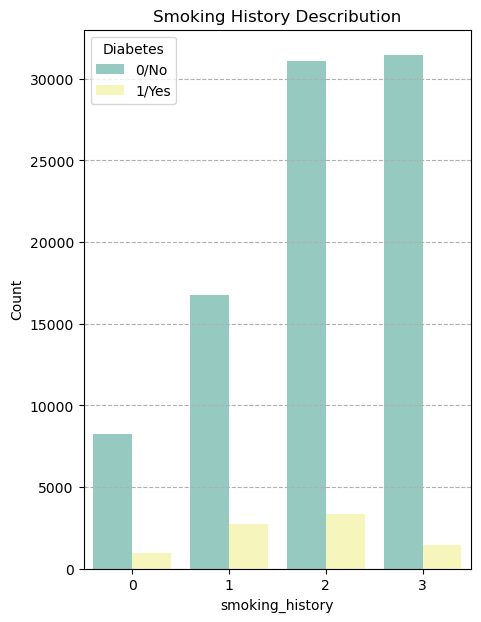

In [9]:
plt.figure(figsize=(5,7))
sns.countplot(x='smoking_history', hue='diabetes', data=df1, palette='Set3')
plt.title("Smoking History Describution")
plt.xlabel("smoking_history")
plt.ylabel("Count")
plt.legend(title="Diabetes", labels=["0/No", "1/Yes"])
plt.grid(axis='y',linestyle='--')
plt.show()

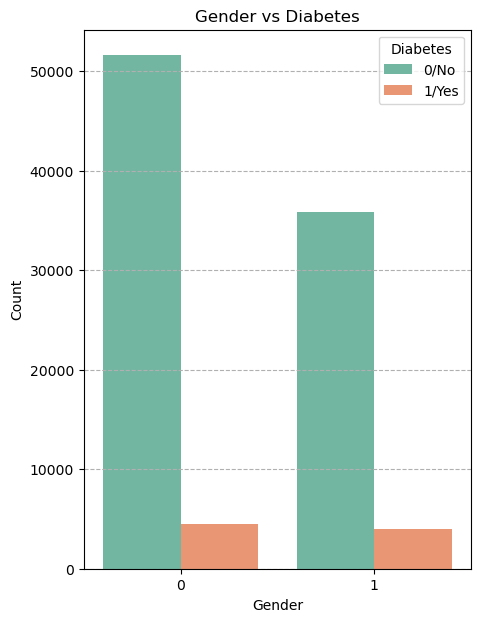

In [10]:
plt.figure(figsize=(5,7))
sns.countplot(x='gender', hue='diabetes', data=df1, palette='Set2')
plt.title("Gender vs Diabetes")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Diabetes", labels=["0/No", "1/Yes"])
plt.grid(axis='y',linestyle='--')
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

X = df1.drop(columns=['diabetes'])
y = df1['diabetes']
feature_names = X.columns.tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# Reset indices so .iloc in the CV loops lines up with the numpy arrays
y_train, y_val, y_test = [s.reset_index(drop=True) for s in (y_train, y_val, y_test)]

for name, s in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, len(s), "diabetic rate:", round(s.mean(), 4))

Train 67165 diabetic rate: 0.0884
Val 14392 diabetic rate: 0.0884
Test 14393 diabetic rate: 0.0884


In [10]:
def count_outliers(df, columns):
    out = {}
    for col in columns:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        out[col] = int(((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum())
    return out

# HbA1c and blood glucose values are retained because extreme values may represent clinically meaningful observations.
print("IQR outliers (train):",
      count_outliers(X_train, ['age', 'bmi', 'hbA1c_level', 'blood_glucose_level']))

# Cap BMI only, using bounds from the training set
q1, q3 = X_train['bmi'].quantile([0.25, 0.75])
iqr = q3 - q1
bmi_low, bmi_high = q1 - 1.5*iqr, q3 + 1.5*iqr
for d in (X_train, X_val, X_test):
    d['bmi'] = d['bmi'].clip(bmi_low, bmi_high)
print(f"BMI capped to [{bmi_low:.2f}, {bmi_high:.2f}]")

IQR outliers (train): {'age': 0, 'bmi': 3634, 'hbA1c_level': 923, 'blood_glucose_level': 1407}
BMI capped to [13.62, 39.70]


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)   # fit on training data only
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

y_train_arr = np.asarray(y_train)
print("Train range:", X_train.min(), X_train.max())
print("Val range:  ", X_val.min(), X_val.max())
print("Test range: ", X_test.min(), X_test.max())

In [ ]:
binary_idx = [feature_names.index(c) for c in ['gender', 'hypertension', 'heart_disease']]
# smoking_history is ONE label-encoded column (0..3), min-max scaled to 0, 1/3, 2/3, 1.
# The old one-hot argmax over a single column set it to 1.0 for every training row.
smoke_idx = feature_names.index('smoking_history')
n_smoke = len(le.classes_) - 1

def fix_synthetic(X):
    """Snap synthetic rows back onto valid values for the discrete columns."""
    X = np.asarray(X, dtype=float).copy()
    X[:, binary_idx] = np.round(X[:, binary_idx])
    X[:, smoke_idx] = np.round(X[:, smoke_idx] * n_smoke) / n_smoke
    return X

def best_threshold(y_true, prob):
    """Threshold that maximises F1 on the validation set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

def summarise(name, prob, thr):
    pred = (prob >= thr).astype(int)
    return {'Model': name, 'Threshold': thr,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob),
            'PR-AUC': average_precision_score(y_test, prob)}

def report(name, val_prob, test_prob):
    thr = best_threshold(y_val, val_prob)
    pred = (test_prob >= thr).astype(int)
    print(f"{name} (threshold = {thr:.3f}, chosen on validation)")
    print(classification_report(y_test, pred, digits=4))
    print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
    print("PR-AUC: ", round(average_precision_score(y_test, test_prob), 4))
    return thr

In [ ]:
!pip install pandas numpy seaborn matplotlib scikit-learn tensorflow torch pytorch-tabnet smote-variants xgboost catboost shap

In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt

# ProWSyn will be applied inside each training fold during cross-validation.
X_train_meta = X_train
y_train_meta = y_train
X_test_meta = X_test
y_test_meta = y_test

print(f"Training data shape: {X_train_meta.shape}")
print(f"Training labels shape: {y_train_meta.shape}")
print(f"Test data shape: {X_test_meta.shape}")
print(f"Test labels shape: {y_test_meta.shape}")

In [ ]:
# CELL: DNN Training with Cross-Validation

import smote_variants as sv
from collections import Counter
from sklearn.model_selection import StratifiedKFold, train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.metrics import Recall

N_FOLDS = 5

# Initialize OOF, test and validation prediction arrays
oof_dnn = np.zeros(len(X_train_meta))
test_dnn_folds = np.zeros((N_FOLDS, len(X_test_meta)))
val_dnn_folds = np.zeros((N_FOLDS, len(X_val)))

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"DNN FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]              # NumPy array
    y_fold_train = y_train_meta.iloc[train_idx].copy()  # Pandas Series, positional indexing

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx].copy()

    # Early-stopping set taken from the TRAINING part of the fold,
    # so the OOF rows (X_fold_val) are never seen during training
    X_fold_train, X_es, y_fold_train, y_es = train_test_split(
        X_fold_train, y_fold_train, test_size=0.1,
        stratify=y_fold_train, random_state=SEED)

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print(f"Fold train: {X_fold_train.shape}")
    print(f"Early-stopping set: {X_es.shape}")
    print(f"Fold validation (OOF): {X_fold_val.shape}")
    print(f"Training class distribution after ProWSyn: {Counter(y_fold_train)}")

    # Build DNN model
    model_dnn = Sequential([
        Input(shape=(X_fold_train.shape[1],)),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(64, activation='tanh'),
        Dropout(0.3),
        Dense(32, activation='tanh'),
        Dropout(0.25),
        Dense(16, activation='tanh'),
        Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(4, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model_dnn.compile(
        optimizer=AdamW(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', Recall(name='recall')]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    # Train
    history_dnn = model_dnn.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_es, y_es),        
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    # OOF prediction
    oof_dnn[val_idx] = model_dnn.predict(X_fold_val, verbose=0).ravel()

    # Test and validation predictions, kept per fold so the meta-learner
    # can be applied to each fold's outputs before averaging
    test_dnn_folds[fold - 1] = model_dnn.predict(X_test_meta, verbose=0).ravel()
    val_dnn_folds[fold - 1] = model_dnn.predict(X_val, verbose=0).ravel()

# Fold-averaged predictions, used by the base-model results cells
test_dnn = test_dnn_folds.mean(axis=0)
val_dnn = val_dnn_folds.mean(axis=0)

print("\nDNN OOF, validation and test predictions completed!")

In [ ]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, precision_recall_curve)

def best_threshold(y_true, prob):
    """Threshold that maximises F1 on the validation set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

dnn_thr = best_threshold(y_val, val_dnn)          # chosen on VALIDATION
dnn_pred = (test_dnn >= dnn_thr).astype(int)      # applied to TEST (fold-averaged)

print(f"DNN Results (threshold = {dnn_thr:.3f}, chosen on validation)")
print(classification_report(y_test, dnn_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_dnn), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_dnn), 4))

In [ ]:
# CELL: TabNet Training with Cross-Validation

from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.model_selection import train_test_split
import torch
import smote_variants as sv
from collections import Counter

# Initialize OOF, test and validation prediction arrays
oof_tabnet = np.zeros(len(X_train_meta))
test_tabnet_folds = np.zeros((N_FOLDS, len(X_test_meta)))
val_tabnet_folds = np.zeros((N_FOLDS, len(X_val)))

tabnet_models = []    

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"TABNET FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = np.asarray(y_train_meta.iloc[val_idx])

    # Early-stopping set taken from the TRAINING part of the fold
    X_fold_train, X_es, y_fold_train, y_es = train_test_split(
        X_fold_train, y_fold_train, test_size=0.1,
        stratify=y_fold_train, random_state=SEED)

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print("Training class distribution:", Counter(y_fold_train))
    print(f"Early-stopping set: {X_es.shape}")
    print(f"Validation (OOF) shape: {X_fold_val.shape}")

    # Build model
    tabnet_model = TabNetClassifier(
        n_d=16,
        n_a=16,
        n_steps=7,
        gamma=1.5,
        lambda_sparse=1e-2,
        optimizer_fn=torch.optim.AdamW,
        optimizer_params=dict(lr=0.005),
        seed=SEED + fold,
        verbose=1
    )

    # Train
    tabnet_model.fit(
        X_fold_train,
        y_fold_train,
        eval_set=[(X_es, np.asarray(y_es))],   
        eval_name=['es'],
        eval_metric=['auc'],
        max_epochs=50,
        patience=5,
        batch_size=1024,
        virtual_batch_size=128
    )

    tabnet_models.append(tabnet_model)         

    # OOF prediction
    oof_tabnet[val_idx] = tabnet_model.predict_proba(X_fold_val)[:, 1]

    # Test and validation predictions, kept per fold so the meta-learner
    # can be applied to each fold's outputs before averaging
    test_tabnet_folds[fold - 1] = tabnet_model.predict_proba(X_test_meta)[:, 1]
    val_tabnet_folds[fold - 1] = tabnet_model.predict_proba(X_val)[:, 1]

# Fold-averaged predictions, used by the base-model results cells
test_tabnet = test_tabnet_folds.mean(axis=0)
val_tabnet = val_tabnet_folds.mean(axis=0)

print("\nTabNet OOF, validation and test predictions completed!")

In [ ]:
tabnet_thr = best_threshold(y_val, val_tabnet)          # chosen on VALIDATION
tabnet_pred = (test_tabnet >= tabnet_thr).astype(int)   # applied to TEST (fold-averaged)

print(f"TabNet Results (threshold = {tabnet_thr:.3f}, chosen on validation)")
print(classification_report(y_test, tabnet_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_tabnet), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_tabnet), 4))

In [ ]:
# CELL: ResNet (tabular, with residual connections) Training with Cross-Validation

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from sklearn.model_selection import train_test_split
from collections import Counter
import smote_variants as sv


def build_resnet(n_features, width=64, n_blocks=3, dropout=0.2):
    inp = layers.Input(shape=(n_features,))
    x = layers.Dense(width)(inp)
    for _ in range(n_blocks):
        h = layers.BatchNormalization()(x)
        h = layers.Dense(width * 2, activation='relu')(h)
        h = layers.Dropout(dropout)(h)
        h = layers.Dense(width)(h)
        x = layers.Add()([x, h])         
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return Model(inp, out)


# Initialize OOF, test and validation prediction arrays
oof_resnet = np.zeros(len(X_train_meta))
test_resnet_folds = np.zeros((N_FOLDS, len(X_test_meta)))
val_resnet_folds = np.zeros((N_FOLDS, len(X_val)))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"RESNET FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx].copy()

    # Early-stopping set taken from the TRAINING part of the fold
    X_fold_train, X_es, y_fold_train, y_es = train_test_split(
        X_fold_train, y_fold_train, test_size=0.1,
        stratify=y_fold_train, random_state=SEED)

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print("Training class distribution:", Counter(y_fold_train))
    print(f"Early-stopping set: {X_es.shape}")
    print(f"Validation (OOF) shape: {X_fold_val.shape}")

    # Build model
    resnet_model = build_resnet(X_fold_train.shape[1])

    resnet_model.compile(
        optimizer=AdamW(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    history = resnet_model.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_es, y_es),    
        epochs=100,
        batch_size=1024,
        callbacks=[early_stop],
        verbose=1
    )

    # OOF prediction
    oof_resnet[val_idx] = resnet_model.predict(X_fold_val, verbose=0).ravel()

    # Test and validation predictions, kept per fold so the meta-learner
    # can be applied to each fold's outputs before averaging
    test_resnet_folds[fold - 1] = resnet_model.predict(X_test_meta, verbose=0).ravel()
    val_resnet_folds[fold - 1] = resnet_model.predict(X_val, verbose=0).ravel()

# Fold-averaged predictions, used by the base-model results cells
test_resnet = test_resnet_folds.mean(axis=0)
val_resnet = val_resnet_folds.mean(axis=0)

print("\nResNet OOF, validation and test predictions completed!")

In [ ]:
resnet_thr = best_threshold(y_val, val_resnet)          # chosen on VALIDATION
resnet_pred = (test_resnet >= resnet_thr).astype(int)   # applied to TEST (fold-averaged)

print(f"ResNet Results (threshold = {resnet_thr:.3f}, chosen on validation)")
print(classification_report(y_test, resnet_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_resnet), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_resnet), 4))

In [ ]:
# CELL: FT-Transformer Training with Cross-Validation
# Attention between features + focal loss WITHOUT oversampling, so its errors
# differ from the ProWSyn-trained MLP / ResNet / TabNet.

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from sklearn.model_selection import train_test_split
from collections import Counter


class FeatureTokenizer(layers.Layer):
    """One learned d-dim token per feature: x_j * W_j + b_j."""
    def __init__(self, d, **kwargs):
        super().__init__(**kwargs)
        self.d = d

    def build(self, input_shape):
        n = input_shape[-1]
        self.w = self.add_weight(shape=(n, self.d), initializer='glorot_uniform', name='w')
        self.b = self.add_weight(shape=(n, self.d), initializer='zeros', name='b')

    def call(self, x):
        return x[..., None] * self.w + self.b


class CLSToken(layers.Layer):
    """Prepend a learned [CLS] token used for the final prediction."""
    def build(self, input_shape):
        self.cls = self.add_weight(shape=(1, 1, input_shape[-1]),
                                   initializer='glorot_uniform', name='cls')

    def call(self, x):
        cls = tf.tile(self.cls, [tf.shape(x)[0], 1, 1])
        return tf.concat([cls, x], axis=1)


def build_ft_transformer(n_features, d=32, n_blocks=2, heads=4, dropout=0.1):
    inp = layers.Input(shape=(n_features,))
    x = CLSToken()(FeatureTokenizer(d)(inp))
    for _ in range(n_blocks):
        h = layers.LayerNormalization()(x)
        h = layers.MultiHeadAttention(heads, d // heads, dropout=dropout)(h, h)
        x = layers.Add()([x, h])
        h = layers.LayerNormalization()(x)
        h = layers.Dense(d * 2, activation='relu')(h)
        h = layers.Dropout(dropout)(h)
        h = layers.Dense(d)(h)
        x = layers.Add()([x, h])
    x = layers.Lambda(lambda t: t[:, 0])(x)      # [CLS] token
    x = layers.LayerNormalization()(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return Model(inp, out)


focal_loss = tf.keras.losses.BinaryFocalCrossentropy(
    apply_class_balancing=True, alpha=0.75, gamma=2.0)

# Initialize OOF, test and validation prediction arrays
oof_ft = np.zeros(len(X_train_meta))
test_ft_folds = np.zeros((N_FOLDS, len(X_test_meta)))
val_ft_folds = np.zeros((N_FOLDS, len(X_val)))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"FT-TRANSFORMER FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()
    X_fold_val = X_train_meta[val_idx]

    # Early-stopping set taken from the TRAINING part of the fold
    X_fold_train, X_es, y_fold_train, y_es = train_test_split(
        X_fold_train, y_fold_train, test_size=0.1,
        stratify=y_fold_train, random_state=SEED)

    # No ProWSyn here: class imbalance is handled by the focal loss
    print("Training class distribution:", Counter(y_fold_train))

    ft_model = build_ft_transformer(X_fold_train.shape[1])
    ft_model.compile(optimizer=AdamW(learning_rate=0.001), loss=focal_loss)

    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=8,
        restore_best_weights=True,
        verbose=1
    )

    ft_model.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_es, y_es),
        epochs=60,
        batch_size=512,
        callbacks=[early_stop],
        verbose=1
    )

    # OOF prediction
    oof_ft[val_idx] = ft_model.predict(X_fold_val, verbose=0).ravel()

    # Test and validation predictions, kept per fold
    test_ft_folds[fold - 1] = ft_model.predict(X_test_meta, verbose=0).ravel()
    val_ft_folds[fold - 1] = ft_model.predict(X_val, verbose=0).ravel()

test_ft = test_ft_folds.mean(axis=0)
val_ft = val_ft_folds.mean(axis=0)

ft_thr = report('FT-Transformer', val_ft, test_ft)

In [ ]:
# CELL: MLP with periodic numerical embeddings (PLR) Training with Cross-Validation
# Each feature is mapped to sin/cos of learned frequencies before the MLP, a
# different input representation from the min-max MLP. Focal loss, no oversampling.

class PeriodicEmbedding(layers.Layer):
    """x_j -> Dense(ReLU)([sin(2*pi*c_j*x_j), cos(2*pi*c_j*x_j)]), per feature."""
    def __init__(self, n_freq=8, sigma=1.0, d=16, **kwargs):
        super().__init__(**kwargs)
        self.n_freq, self.sigma, self.d = n_freq, sigma, d

    def build(self, input_shape):
        n = input_shape[-1]
        self.c = self.add_weight(
            shape=(n, self.n_freq), name='c',
            initializer=tf.keras.initializers.RandomNormal(0.0, self.sigma))
        self.w = self.add_weight(shape=(n, 2 * self.n_freq, self.d),
                                 initializer='glorot_uniform', name='w')
        self.b = self.add_weight(shape=(n, self.d), initializer='zeros', name='b')

    def call(self, x):
        v = 2 * np.pi * x[..., None] * self.c                  # (batch, n, k)
        v = tf.concat([tf.sin(v), tf.cos(v)], axis=-1)          # (batch, n, 2k)
        return tf.nn.relu(tf.einsum('bnk,nkd->bnd', v, self.w) + self.b)


def build_plr_mlp(n_features, dropout=0.2):
    inp = layers.Input(shape=(n_features,))
    x = layers.Flatten()(PeriodicEmbedding()(inp))
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return Model(inp, out)


# Initialize OOF, test and validation prediction arrays
oof_plr = np.zeros(len(X_train_meta))
test_plr_folds = np.zeros((N_FOLDS, len(X_test_meta)))
val_plr_folds = np.zeros((N_FOLDS, len(X_val)))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"PLR-MLP FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()
    X_fold_val = X_train_meta[val_idx]

    # Early-stopping set taken from the TRAINING part of the fold
    X_fold_train, X_es, y_fold_train, y_es = train_test_split(
        X_fold_train, y_fold_train, test_size=0.1,
        stratify=y_fold_train, random_state=SEED)

    plr_model = build_plr_mlp(X_fold_train.shape[1])
    plr_model.compile(optimizer=AdamW(learning_rate=0.001), loss=focal_loss)

    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=8,
        restore_best_weights=True,
        verbose=1
    )

    plr_model.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_es, y_es),
        epochs=60,
        batch_size=512,
        callbacks=[early_stop],
        verbose=1
    )

    # OOF prediction
    oof_plr[val_idx] = plr_model.predict(X_fold_val, verbose=0).ravel()

    # Test and validation predictions, kept per fold
    test_plr_folds[fold - 1] = plr_model.predict(X_test_meta, verbose=0).ravel()
    val_plr_folds[fold - 1] = plr_model.predict(X_val, verbose=0).ravel()

test_plr = test_plr_folds.mean(axis=0)
val_plr = val_plr_folds.mean(axis=0)

plr_thr = report('PLR-MLP', val_plr, test_plr)

In [ ]:
# Meta-features: base-model logits (undo ProWSyn's squashing toward 1)

from itertools import combinations
from scipy.special import logit, expit
from sklearn.metrics import precision_score, recall_score, f1_score


def to_logit(p):
    return logit(np.clip(p, 1e-6, 1 - 1e-6))


base_oof = {'DNN': oof_dnn, 'TabNet': oof_tabnet, 'ResNet': oof_resnet,
            'FT-Transformer': oof_ft, 'PLR-MLP': oof_plr}
base_val_folds = {'DNN': val_dnn_folds, 'TabNet': val_tabnet_folds,
                  'ResNet': val_resnet_folds, 'FT-Transformer': val_ft_folds,
                  'PLR-MLP': val_plr_folds}
base_test_folds = {'DNN': test_dnn_folds, 'TabNet': test_tabnet_folds,
                   'ResNet': test_resnet_folds, 'FT-Transformer': test_ft_folds,
                   'PLR-MLP': test_plr_folds}

# The original combinations, plus the new models and all five together
combos = {
    'DNN + TabNet': ['DNN', 'TabNet'],
    'DNN + ResNet': ['DNN', 'ResNet'],
    'TabNet + ResNet': ['TabNet', 'ResNet'],
    'DNN + TabNet + ResNet': ['DNN', 'TabNet', 'ResNet'],
    'ResNet + FT-Transformer + PLR-MLP': ['ResNet', 'FT-Transformer', 'PLR-MLP'],
    'All 5': list(base_oof),
}


def meta_inputs(names):
    """OOF logits for training; one val/test matrix per fold for inference."""
    Z_train = np.column_stack([to_logit(base_oof[n]) for n in names])
    Z_val = [np.column_stack([to_logit(base_val_folds[n][k]) for n in names])
             for k in range(N_FOLDS)]
    Z_test = [np.column_stack([to_logit(base_test_folds[n][k]) for n in names])
              for k in range(N_FOLDS)]
    return Z_train, Z_val, Z_test


# Diversity check: the lower these correlations, the more stacking can help
print("Spearman correlation of OOF predictions:")
print(pd.DataFrame(base_oof).corr(method='spearman').round(3))

# Test probabilities of every model, for the bootstrap CIs at the end
test_probs = {'DNN': test_dnn, 'TabNet': test_tabnet, 'ResNet': test_resnet,
              'FT-Transformer': test_ft, 'PLR-MLP': test_plr}

In [ ]:
# Baseline: plain average of base-model logits (no learned meta-learner)

avg_rows = []
for combo, names in combos.items():
    _, Z_val, Z_test = meta_inputs(names)
    val_prob = np.mean([expit(z.mean(axis=1)) for z in Z_val], axis=0)
    test_prob = np.mean([expit(z.mean(axis=1)) for z in Z_test], axis=0)
    thr = best_threshold(y_val, val_prob)
    avg_rows.append(summarise(f'Logit average: {combo}', test_prob, thr))
    test_probs[f'Logit average: {combo}'] = test_prob

avg_results = pd.DataFrame(avg_rows)
avg_results

In [ ]:
# Gated DL meta-learner: a small network reads the patient's features and
# decides how much to trust each base model (logits + passthrough features)

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW


def build_gated_meta(n_base, n_feat):
    z = layers.Input(shape=(n_base,), name='base_logits')
    x = layers.Input(shape=(n_feat,), name='features')
    h = layers.Dense(32, activation='relu')(x)
    h = layers.Dropout(0.2)(h)
    w = layers.Dense(n_base, activation='softmax', name='gate')(h)
    mix = layers.Dot(axes=1)([w, z])
    # Outputs a LOGIT. Starts as identity (= logit average) and learns scale + bias;
    # a sigmoid output here can saturate on large base logits and never recover.
    out = layers.Dense(1, kernel_initializer='ones', name='calibration')(mix)
    return Model([z, x], out)


def fit_meta(Z_train):
    # Stratified early-stopping split (validation_split took the last 20% of rows)
    Ztr, Zes, Xtr, Xes, ytr, yes = train_test_split(
        Z_train, X_train, y_train_arr, test_size=0.15,
        stratify=y_train_arr, random_state=SEED)
    meta = build_gated_meta(Z_train.shape[1], X_train.shape[1])
    meta.compile(optimizer=AdamW(learning_rate=0.001),
                 loss=tf.keras.losses.BinaryCrossentropy(from_logits=True))
    meta.fit([Ztr, Xtr], ytr,
             validation_data=([Zes, Xes], yes),
             epochs=200, batch_size=256, verbose=0,
             callbacks=[EarlyStopping(monitor='val_loss', patience=15,
                                      restore_best_weights=True)])
    return meta


gated_rows, gated_models = [], {}
for combo, names in combos.items():
    Z_train, Z_val, Z_test = meta_inputs(names)
    meta = fit_meta(Z_train)

    # Apply the meta-learner to each fold's predictions, then average
    val_prob = np.mean([expit(meta.predict([z, X_val], verbose=0).ravel())
                        for z in Z_val], axis=0)
    test_prob = np.mean([expit(meta.predict([z, X_test], verbose=0).ravel())
                         for z in Z_test], axis=0)

    thr = best_threshold(y_val, val_prob)
    gated_rows.append(summarise(f'Gated DL meta: {combo}', test_prob, thr))
    test_probs[f'Gated DL meta: {combo}'] = test_prob
    gated_models[combo] = meta

gated_results = pd.DataFrame(gated_rows)
gated_results

In [ ]:
# Average gate weights on the test set: how much the meta-learner trusts each
# base model, for non-diabetic (0) vs diabetic (1) patients

names = combos['All 5']
gate = Model(gated_models['All 5'].inputs,
             gated_models['All 5'].get_layer('gate').output)
_, _, Z_test = meta_inputs(names)
w = np.mean([gate.predict([z, X_test], verbose=0) for z in Z_test], axis=0)
pd.DataFrame(w, columns=names).groupby(np.asarray(y_test)).mean().round(3)

In [ ]:
# DNN Results

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

dnn_prob = test_dnn                               # 5-fold averaged test predictions
dnn_pred = (dnn_prob >= dnn_thr).astype(int)      # threshold tuned on validation

dnn_results = pd.DataFrame([{
    'Model': 'DNN',
    'Base Models': 'DNN',
    'Threshold': dnn_thr,
    'Accuracy': accuracy_score(y_test, dnn_pred),
    'Precision': precision_score(y_test, dnn_pred),
    'Recall': recall_score(y_test, dnn_pred),
    'F1': f1_score(y_test, dnn_pred),
    'ROC-AUC': roc_auc_score(y_test, dnn_prob),
    'PR-AUC': average_precision_score(y_test, dnn_prob)
}])

print(f"DNN Results (threshold = {dnn_thr:.3f})")
print(classification_report(y_test, dnn_pred, digits=4))
print(dnn_results)

In [ ]:
# TabNet Results

tabnet_prob = test_tabnet                                   # 5-fold averaged
tabnet_pred = (tabnet_prob >= tabnet_thr).astype(int)       # tuned threshold

print(f"TabNet Results (threshold = {tabnet_thr:.3f}), Classification Report:\n")
print(classification_report(y_test, tabnet_pred, digits=4))

print("ROC-AUC:", roc_auc_score(y_test, tabnet_prob))
print("PR-AUC:", average_precision_score(y_test, tabnet_prob))

tabnet_results = pd.DataFrame([{
    'Model': 'TabNet',
    'Base Models': 'TabNet',
    'Threshold': tabnet_thr,
    'Accuracy': accuracy_score(y_test, tabnet_pred),
    'Precision': precision_score(y_test, tabnet_pred),
    'Recall': recall_score(y_test, tabnet_pred),
    'F1': f1_score(y_test, tabnet_pred),
    'ROC-AUC': roc_auc_score(y_test, tabnet_prob),
    'PR-AUC': average_precision_score(y_test, tabnet_prob)
}])

tabnet_results

In [ ]:
# ResNet Results

resnet_prob = test_resnet                                   # 5-fold averaged
resnet_pred = (resnet_prob >= resnet_thr).astype(int)       # tuned threshold

print(f"ResNet Results (threshold = {resnet_thr:.3f}), Classification Report:\n")
print(classification_report(y_test, resnet_pred, digits=4))

print("ROC-AUC:", roc_auc_score(y_test, resnet_prob))
print("PR-AUC:", average_precision_score(y_test, resnet_prob))

resnet_results = pd.DataFrame([{
    'Model': 'ResNet',
    'Base Models': 'ResNet',
    'Threshold': resnet_thr,
    'Accuracy': accuracy_score(y_test, resnet_pred),
    'Precision': precision_score(y_test, resnet_pred),
    'Recall': recall_score(y_test, resnet_pred),
    'F1': f1_score(y_test, resnet_pred),
    'ROC-AUC': roc_auc_score(y_test, resnet_prob),
    'PR-AUC': average_precision_score(y_test, resnet_prob)
}])

resnet_results

In [ ]:
# FT-Transformer and PLR-MLP Results

new_base_results = pd.DataFrame([
    summarise('FT-Transformer', test_ft, ft_thr),
    summarise('PLR-MLP', test_plr, plr_thr),
])
new_base_results

In [ ]:
# Summary of Base Models + Meta-Learners

all_results = pd.concat([
    dnn_results,
    tabnet_results,
    resnet_results,
    new_base_results,
    avg_results,
    gated_results
], ignore_index=True)

# 'Base Models' is only filled for the 3 original base rows, so drop it
all_results = all_results.drop(columns=['Base Models'])

# Round for readability
all_results = all_results.round(4)

# Save a copy for the paper
all_results.to_csv("all_results.csv", index=False)

all_results

In [ ]:
# 95% bootstrap confidence intervals for PR-AUC and ROC-AUC on the test set.
# Differences between models whose intervals overlap heavily are not meaningful.

N_BOOT = 1000
rng = np.random.default_rng(SEED)
y_test_arr = np.asarray(y_test)
pos = np.where(y_test_arr == 1)[0]
neg = np.where(y_test_arr == 0)[0]

boot_idx = [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
            for _ in range(N_BOOT)]   # stratified resamples keep the class ratio

ci_rows = []
for name, prob in test_probs.items():
    pr = [average_precision_score(y_test_arr[b], prob[b]) for b in boot_idx]
    roc = [roc_auc_score(y_test_arr[b], prob[b]) for b in boot_idx]
    ci_rows.append({
        'Model': name,
        'PR-AUC': average_precision_score(y_test_arr, prob),
        'PR-AUC 2.5%': np.percentile(pr, 2.5),
        'PR-AUC 97.5%': np.percentile(pr, 97.5),
        'ROC-AUC': roc_auc_score(y_test_arr, prob),
        'ROC-AUC 2.5%': np.percentile(roc, 2.5),
        'ROC-AUC 97.5%': np.percentile(roc, 97.5),
    })

ci_results = (pd.DataFrame(ci_rows)
              .sort_values('PR-AUC', ascending=False)
              .round(4)
              .reset_index(drop=True))
ci_results.to_csv("bootstrap_ci.csv", index=False)
ci_results